# make_grid demo notebook

This notebook demonstrates how to use `make_grid.py` to build a
`(z, E(B-V), template, band)` four-dimensional photometric grid from FSPS templates and
multi-band filter response curves, and how to use it as a template-fitting engine.

| Section | Content |
| --- | --- |
| 1 | Build the 401 × 50 × 12 × 11 grid with the default configuration |
| 2 | Read the 11-band fluxes of a single grid node and plot the filter curves |
| 3 | Photometric redshift + template + E(B-V) fit with amplitude marginalization, using the grid |
| 4 | Custom configuration (band subset / smaller grid) and wavelength-grid convergence check |
| 5 | Write the grid to disk, reload it, and inspect the diagnostics figure |
| 6 | Equivalent command-line usage, plus a bitwise consistency check against the original notebook product |

**Requirements**: `pip install -r requirements.txt`. This file can be opened either in
`code/make_grid/` or at the repository root; the first code cell locates the package directory
automatically. The full default grid takes about 4 s on this machine, and the whole notebook
runs in under 10 s.


In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt


def find_package_dir() -> Path:
    # Walk up from the current working directory looking for a directory that contains
    # make_grid.py (works both when opened inside the package and when opened at the repo root)
    cwd = Path.cwd()
    for base in (cwd, *cwd.parents):
        for cand in (base, base / "make_grid", base / "code" / "make_grid"):
            if (cand / "make_grid.py").is_file():
                return cand.resolve()
    raise FileNotFoundError("make_grid.py not found; run from code/make_grid/ or the repository root")


PKG = find_package_dir()
if str(PKG) not in sys.path:
    sys.path.insert(0, str(PKG))

ROOT = PKG.parents[1]          # repository root: two levels above code/make_grid


def rel_path(path) -> str:
    # Present absolute paths as repository-relative paths when possible, so outputs can be shared
    target = Path(path).resolve()
    for base in (Path.cwd().resolve(), ROOT.resolve()):
        try:
            return str(target.relative_to(base))
        except ValueError:
            continue
    return str(target)


import make_grid

print("make_grid version:", make_grid.__version__)
print("package directory:", PKG.name)
print("default bands:", ", ".join(make_grid.DEFAULT_BANDS))


make_grid version: 1.0.0
package directory: make_grid
default bands: GALEX_NUV, CFHT_ustar, HSC_g, HSC_r, HSC_i, HSC_z, HSC_y, UVISTA_J, UVISTA_Ks, IRAC_CH1, IRAC_CH2


## 1. Building the default grid

For every redshift $z$, every extra dust attenuation $E(B-V)$ and every template spectrum
$f_\lambda$, the band fluxes are synthesized in the observed frame with a non-uniform
trapezoidal integral:

$$F_b(z, E(B-V), t) \;\propto\; \frac{\int f_\lambda(\lambda)\,10^{-0.4\,k(\lambda)E(B-V)}\,T_{\rm IGM}(\lambda,z)\,\lambda\,R_b\big((1+z)\lambda\big)\,d\lambda}{\int R_b\big((1+z)\lambda\big)\,d\lambda/\lambda}$$

where $k(\lambda) = R_V \cdot G_{23}(\lambda) = A(\lambda)/E(B-V)$ ($G_{23}$ is normalized to 1
in the V band), $T_{\rm IGM}$ is the Inoue et al. (2014) IGM transmission (applied only for
$\lambda<1300$ Å), and $R_b$ is the filter response curve. Finally each node is normalized to
25 AB in the reference band (default `UVISTA_Ks`). The common (luminosity) distance factor
and the overall $(1+z)$ scaling are absorbed by the free amplitude, so the grid only carries the
**relative flux shape**; fluxes are in μJy (AB 23.9 = 1 μJy).


In [2]:
config = make_grid.GridConfig()
print("config:", config.to_dict())

grid = make_grid.build_grid(config, progress_every=0)   # in memory only; returns a TemplateGrid

print()
print(f"flux shape (z, E(B-V), template, band) = {grid.shape}")
print(f"nodes = {grid.n_nodes:,}")
print(f"redshift : {grid.redshift[0]:g} -> {grid.redshift[-1]:g}, {grid.redshift.size} points, dz = {grid.redshift[1] - grid.redshift[0]:g}")
print(f"E(B-V)   : {grid.ebv[0]:g} -> {grid.ebv[-1]:g}, {grid.ebv.size} points")
print(f"templates: {len(grid.template_names)} ({grid.template_names[0]} ... {grid.template_names[-1]})")
print(f"bands    : {len(grid.filter_names)}")
wg = grid.metadata["wavelength_grid"]
print(f"common wavelength grid: {wg['n']} points, {wg['min_A']:.2f} - {wg['max_A']:.2f} Angstrom")


config: {'bands': ['GALEX_NUV', 'CFHT_ustar', 'HSC_g', 'HSC_r', 'HSC_i', 'HSC_z', 'HSC_y', 'UVISTA_J', 'UVISTA_Ks', 'IRAC_CH1', 'IRAC_CH2'], 'z': {'min': 0.0, 'max': 4.0, 'n': 401}, 'ebv': {'min': 0.0, 'max': 1.0, 'n': 50}, 'rv': 3.1, 'ref_band': 'UVISTA_Ks', 'ref_mag': 25.0, 'ab_zeropoint_uJy': 23.9, 'n_wave': 16000}


Grid complete: (401, 50, 12, 11), 240,600 nodes, 2.1 s

flux shape (z, E(B-V), template, band) = (401, 50, 12, 11)
nodes = 240,600
redshift : 0 -> 4, 401 points, dz = 0.01
E(B-V)   : 0 -> 1, 50 points
templates: 12 (tweak_fsps_QSF_12_v3_001 ... tweak_fsps_QSF_12_v3_012)
bands    : 11
common wavelength grid: 21043 points, 332.64 - 53762.30 Angstrom


In [3]:
ref_flux = make_grid.reference_flux_uJy(grid.ref_mag)
i_ref = grid.filter_names.index(grid.ref_filter)
print(f"reference band {grid.ref_filter} @ {grid.ref_mag:g} AB -> {ref_flux:.6f} uJy")
print("reference band equals this value at every node:", np.allclose(grid.flux[..., i_ref], ref_flux))
print("flux range: %.3e .. %.3e uJy" % (grid.flux.min(), grid.flux.max()))
print("negative-flux nodes:", int((grid.flux < 0).sum()), "/ zero-flux nodes:", int((grid.flux == 0).sum()))
print("config_hash:", grid.config_hash[:16], "...")


reference band UVISTA_Ks @ 25 AB -> 0.363078 uJy
reference band equals this value at every node: True
flux range: 1.063e-16 .. 1.540e+02 uJy
negative-flux nodes: 0 / zero-flux nodes: 0
config_hash: cb60da00ddeb10e6 ...


## 2. One grid node: observed-frame fluxes in 11 bands

Take the node at $z=1.0$, template 005, $E(B-V)=0.2$, read off the fluxes in the 11 bands, and
plot them against the response-weighted centroid of each filter (the "effective wavelength");
the left panel shows the 11 filter response curves themselves.


In [4]:
i_z = int(np.argmin(np.abs(grid.redshift - 1.0)))
i_e = int(np.argmin(np.abs(grid.ebv - 0.2)))
i_t = 4                                   # 0-based -> tweak_fsps_QSF_12_v3_005
node = grid.flux[i_z, i_e, i_t]

profiles, filter_rows, _manifest = make_grid.load_filters(
    PKG / "filters", PKG / "filters" / "manifest.json", grid.filter_names
)
lam_eff = np.array([np.average(p[0], weights=p[1]) for p in (profiles[b] for b in grid.filter_names)])

print(f"node: z = {grid.redshift[i_z]:.2f}, template = {grid.template_names[i_t]}, E(B-V) = {grid.ebv[i_e]:.3f}")
for band, flux in zip(grid.filter_names, node):
    print(f"  {band:11s} {flux:12.6f} uJy   (-2.5log10(F/F_ref) = {-2.5 * np.log10(flux / ref_flux):8.3f} mag)")


node: z = 1.00, template = tweak_fsps_QSF_12_v3_005, E(B-V) = 0.204
  GALEX_NUV       0.000005 uJy   (-2.5log10(F/F_ref) =   12.192 mag)
  CFHT_ustar      0.000026 uJy   (-2.5log10(F/F_ref) =   10.380 mag)
  HSC_g           0.000112 uJy   (-2.5log10(F/F_ref) =    8.779 mag)
  HSC_r           0.001555 uJy   (-2.5log10(F/F_ref) =    5.920 mag)
  HSC_i           0.008062 uJy   (-2.5log10(F/F_ref) =    4.134 mag)
  HSC_z           0.024271 uJy   (-2.5log10(F/F_ref) =    2.937 mag)
  HSC_y           0.037975 uJy   (-2.5log10(F/F_ref) =    2.451 mag)
  UVISTA_J        0.097237 uJy   (-2.5log10(F/F_ref) =    1.430 mag)
  UVISTA_Ks       0.363078 uJy   (-2.5log10(F/F_ref) =   -0.000 mag)
  IRAC_CH1        0.580823 uJy   (-2.5log10(F/F_ref) =   -0.510 mag)
  IRAC_CH2        0.449568 uJy   (-2.5log10(F/F_ref) =   -0.232 mag)


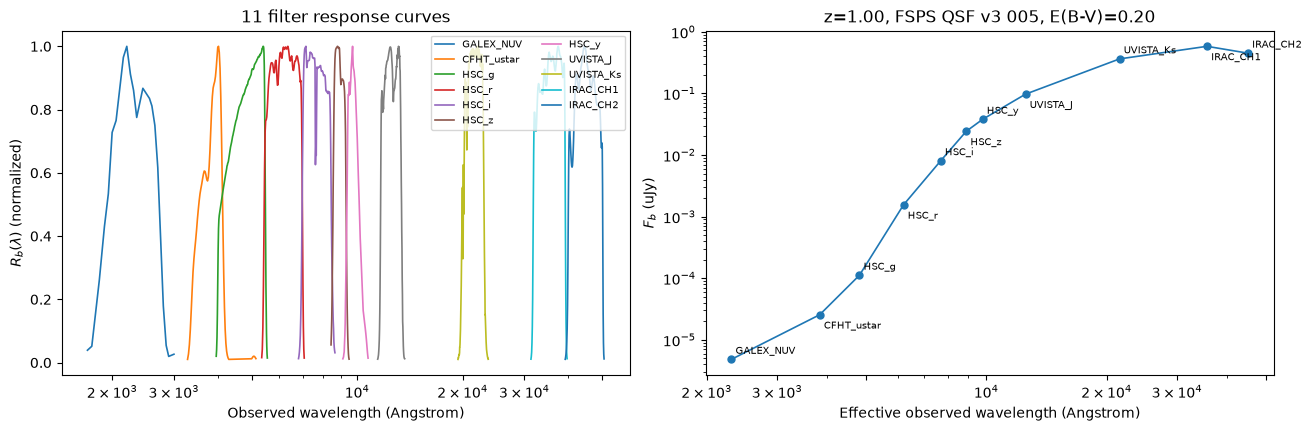

In [5]:
import matplotlib.ticker as mtick

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)

for band in grid.filter_names:
    fw, fr = profiles[band]
    sel = fr > 0.01 * fr.max()
    ax1.plot(fw[sel], fr[sel] / fr.max(), lw=1.2, label=band)
ax1.set_xscale("log")
ax1.set_xlabel("Observed wavelength (Angstrom)")
ax1.set_ylabel(r"$R_b(\lambda)$ (normalized)")
ax1.set_title("11 filter response curves")
ax1.legend(fontsize=7, ncol=2, loc="upper right")

ax2.loglog(lam_eff, node, "o-", ms=5, lw=1.2)
for j, (band, x, y) in enumerate(zip(grid.filter_names, lam_eff, node)):
    ax2.annotate(band, (x, y), fontsize=7, textcoords="offset points",
                 xytext=(3, 4 if j % 2 == 0 else -10))
for ax in (ax1, ax2):
    ax.xaxis.set_major_locator(mtick.LogLocator(base=10, subs=(1.0, 2.0, 3.0, 5.0), numticks=12))
    ax.xaxis.set_minor_formatter(mtick.NullFormatter())
ax2.set_xlabel("Effective observed wavelength (Angstrom)")
ax2.set_ylabel(r"$F_b$ (uJy)")
ax2.set_title(f"z={grid.redshift[i_z]:.2f}, {grid.template_names[i_t].replace('tweak_fsps_QSF_12_v3_', 'FSPS QSF v3 ')}, E(B-V)={grid.ebv[i_e]:.2f}")
plt.show()

## 3. Fitting demo: photometric redshift + template + E(B-V) with analytic amplitude marginalization

Each grid node gives the relative fluxes $m_b$ in the 11 bands, and the observed flux is written
as $f_b = a\,m_b$, where $a$ absorbs the overall factor (luminosity distance, etc.). For a
fixed $a$,

$$\chi^2(z,t,E) = \sum_b \frac{(f_b - a\,m_b)^2}{\sigma_b^2},$$

extremizing over $a$ eliminates the amplitude analytically:
$\hat a = \frac{\sum_b w_b f_b m_b}{\sum_b w_b m_b^2}$, and after marginalization

$$\chi^2_{\rm marg} = \sum_b w_b f_b^2 - \frac{\left(\sum_b w_b f_b m_b\right)^2}{\sum_b w_b m_b^2}.$$

Below we take one node from the grid ($z=1.2$, template 007, $E(B-V)=0.3$), scale it by a
brightness factor of 0.35, add 5% photometric noise to build a set of "observations", and then
run this search over **all 240,600 nodes**.


In [6]:
rng = np.random.default_rng(2024)
i_zt, i_et, i_tt = 120, 15, 6          # z = 1.20, E(B-V) = 0.306, template 007
amp_true = 0.35
sigma_frac = 0.05

f_true = grid.flux[i_zt, i_et, i_tt]
f_obs = amp_true * f_true * (1.0 + sigma_frac * rng.standard_normal(f_true.size))
sigma = sigma_frac * f_obs

print(f"truth: z = {grid.redshift[i_zt]:.2f}, template = {grid.template_names[i_tt]}, E(B-V) = {grid.ebv[i_et]:.3f}, amplitude a = {amp_true}")
for band, fo in zip(grid.filter_names, f_obs):
    print(f"  {band:11s} {fo:12.6f} uJy")


truth: z = 1.20, template = tweak_fsps_QSF_12_v3_007, E(B-V) = 0.306, amplitude a = 0.35
  GALEX_NUV       0.002397 uJy
  CFHT_ustar      0.013840 uJy
  HSC_g           0.011036 uJy
  HSC_r           0.020455 uJy
  HSC_i           0.033144 uJy
  HSC_z           0.051670 uJy
  HSC_y           0.058633 uJy
  UVISTA_J        0.073588 uJy
  UVISTA_Ks       0.138580 uJy
  IRAC_CH1        0.136836 uJy
  IRAC_CH2        0.123184 uJy


In [7]:
F = grid.flux.reshape(-1, grid.flux.shape[-1])          # (N, 11) uJy
w = 1.0 / sigma ** 2
wf = w * f_obs

den = (F ** 2) @ w                                        # sum_b w_b m_b^2
num = F @ wf                                             # sum_b w_b f_b m_b
chi2 = (wf * f_obs).sum() - num ** 2 / den
chi2 = np.where(den > 0, chi2, np.inf)
chi2_z = chi2.reshape(grid.shape[:-1]).min(axis=(1, 2))   # minimize over template and E(B-V)

k = int(np.argmin(chi2))
iz, ie, it = np.unravel_index(k, grid.shape[:-1])
amp_best = num[k] / den[k]

print(f"best fit: z = {grid.redshift[iz]:.2f}, template = {grid.template_names[it]}, E(B-V) = {grid.ebv[ie]:.3f}")
print(f"amplitude: a = {amp_best:.4f} (truth {amp_true}); chi2_marg = {chi2[k]:.2f}, number of data points = {f_obs.size}")
print(f"matches truth: z match={grid.redshift[iz] == grid.redshift[i_zt]}, template match={it == i_tt}, E(B-V) match={grid.ebv[ie] == grid.ebv[i_et]}")

pz = np.exp(-0.5 * (chi2_z - chi2_z.min()))    # approximate posterior in z: p(z) ∝ exp(-chi2_z/2)
pz /= pz.sum()
cdf = np.cumsum(pz)
z_lo, z_hi = grid.redshift[np.searchsorted(cdf, 0.16)], grid.redshift[np.searchsorted(cdf, 0.84)]
print(f"z posterior: peak {grid.redshift[int(np.argmax(pz))]:.2f}, 68% interval [{z_lo:.2f}, {z_hi:.2f}], mean {np.sum(pz * grid.redshift):.3f}")


best fit: z = 1.20, template = tweak_fsps_QSF_12_v3_007, E(B-V) = 0.306
amplitude: a = 0.3581 (truth 0.35); chi2_marg = 10.09, number of data points = 11
matches truth: z match=True, template match=True, E(B-V) match=True
z posterior: peak 1.20, 68% interval [1.20, 1.23], mean 1.213


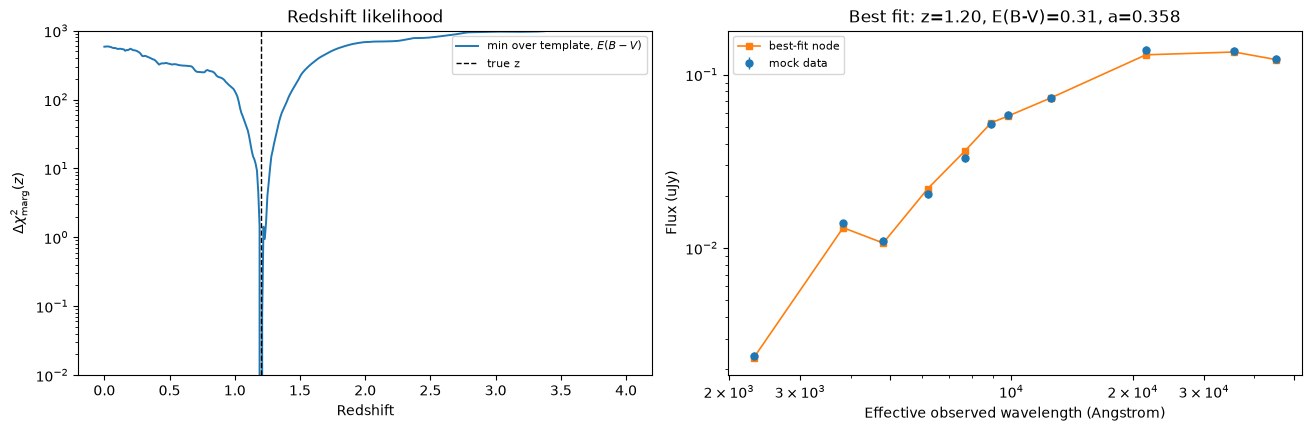

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)

ax1.plot(grid.redshift, chi2_z - chi2_z.min(), lw=1.4, label=r"min over template, $E(B-V)$")
ax1.axvline(grid.redshift[i_zt], color="k", ls="--", lw=1, label="true z")
ax1.set_yscale("log")
ax1.set_ylim(1e-2, 1e3)
ax1.set_xlabel("Redshift")
ax1.set_ylabel(r"$\Delta\chi^2_{\rm marg}(z)$")
ax1.set_title("Redshift likelihood")
ax1.legend(fontsize=8)

ax2.errorbar(lam_eff, f_obs, yerr=sigma, fmt="o", ms=5, lw=1, label="mock data")
ax2.loglog(lam_eff, amp_best * grid.flux[iz, ie, it], "s-", ms=4, lw=1.2, label="best-fit node")
ax2.set_xlabel("Effective observed wavelength (Angstrom)")
ax2.set_ylabel("Flux (uJy)")
ax2.set_title(f"Best fit: z={grid.redshift[iz]:.2f}, E(B-V)={grid.ebv[ie]:.2f}, a={amp_best:.3f}")
ax2.xaxis.set_major_locator(mtick.LogLocator(base=10, subs=(1.0, 2.0, 3.0, 5.0), numticks=12))
ax2.xaxis.set_minor_formatter(mtick.NullFormatter())
ax2.legend(fontsize=8)
plt.show()

## 4. Custom configuration and wavelength-grid convergence check

`GridConfig` can switch the band subset, the redshift/attenuation ranges and sampling
density, $R_V$, the reference band, and the number of points on the common wavelength grid.
Below we first build a small grid with 8 bands, $n_z=101$ and $n_{\rm EBV}=10$ (the reference
band `UVISTA_Ks` must be among the bands), then check the convergence of the integral
with two different `n_wave` values.


In [9]:
BANDS_SUB = ("GALEX_NUV", "HSC_g", "HSC_r", "HSC_i", "HSC_z", "UVISTA_Ks", "IRAC_CH1", "IRAC_CH2")
config_sub = make_grid.GridConfig(bands=BANDS_SUB, n_z=101, n_ebv=10, z_max=3.0, n_wave=4000)
grid_sub = make_grid.build_grid(config_sub, progress_every=0)

wg_sub = grid_sub.metadata["wavelength_grid"]
print(f"sub-grid shape = {grid_sub.shape}, nodes = {grid_sub.n_nodes:,}")
print("bands:", ", ".join(grid_sub.filter_names))
print(f"wavelength grid: {wg_sub['n']} points, {wg_sub['min_A']:.1f} - {wg_sub['max_A']:.1f} Angstrom")
print("reference band still normalized to 25 AB:", np.allclose(grid_sub.flux[..., grid_sub.filter_names.index("UVISTA_Ks")],
                                          make_grid.reference_flux_uJy(25.0)))


Grid complete: (101, 10, 12, 8), 12,120 nodes, 0.1 s
sub-grid shape = (101, 10, 12, 8), nodes = 12,120
bands: GALEX_NUV, HSC_g, HSC_r, HSC_i, HSC_z, UVISTA_Ks, IRAC_CH1, IRAC_CH2
wavelength grid: 9034 points, 415.8 - 53762.3 Angstrom
reference band still normalized to 25 AB: True


In [10]:
# Fix the (z, E(B-V), template) axes and only refine n_wave by 4x, to see how much the fluxes change
small = dict(bands=BANDS_SUB, n_z=21, n_ebv=5)
coarse = make_grid.build_grid(make_grid.GridConfig(n_wave=2000, **small), progress_every=0)
fine = make_grid.build_grid(make_grid.GridConfig(n_wave=8000, **small), progress_every=0)

both = (fine.flux > 1e-3) & (coarse.flux > 1e-3)      # compare only nodes with a strong enough signal
dmag = -2.5 * np.log10(coarse.flux[both] / fine.flux[both])
print(f"nodes compared: {both.sum():,} / {fine.flux.size:,} (the rest are too faint, dominated by numerical noise)")
print(f"max |dmag| = {np.abs(dmag).max():.2e} mag, median = {np.median(np.abs(dmag)):.2e} mag, fraction above 0.01 mag = {np.mean(np.abs(dmag) > 0.01):.2%}")


Grid complete: (21, 5, 12, 8), 1,260 nodes, 0.0 s
Grid complete: (21, 5, 12, 8), 1,260 nodes, 0.0 s
nodes compared: 6,728 / 10,080 (the rest are too faint, dominated by numerical noise)
max |dmag| = 1.48e-03 mag, median = 4.50e-05 mag, fraction above 0.01 mag = 0.00%


## 5. Saving, loading and diagnostics

On top of `build_grid()`, `run()` handles writing to disk:
`output/fsps_11band_grid.npz` (axes, names, `config_hash`),
`output/grid_metadata.json` (configuration, input file sha256, software versions,
statistics) and `output/grid_diagnostics.png`. Re-running the same configuration hits
the content-hash cache and only rewrites the metadata and the diagnostics figure.


content hash matches, reusing cache output/fsps_11band_grid.npz (use --force to recompute)
Wrote: output/grid_metadata.json


Wrote: output/grid_diagnostics.png
cache hit: True / elapsed 0.43 s
  grid        output/fsps_11band_grid.npz  (18343.1 KiB)
  metadata    output/grid_metadata.json  (8.5 KiB)
  diagnostics output/grid_diagnostics.png  (268.7 KiB)
npz keys after reload: ['config_hash', 'ebv', 'filter_names', 'flux', 'metadata', 'redshift', 'ref_filter', 'ref_mag', 'template_names']
bitwise identical to the original object: True


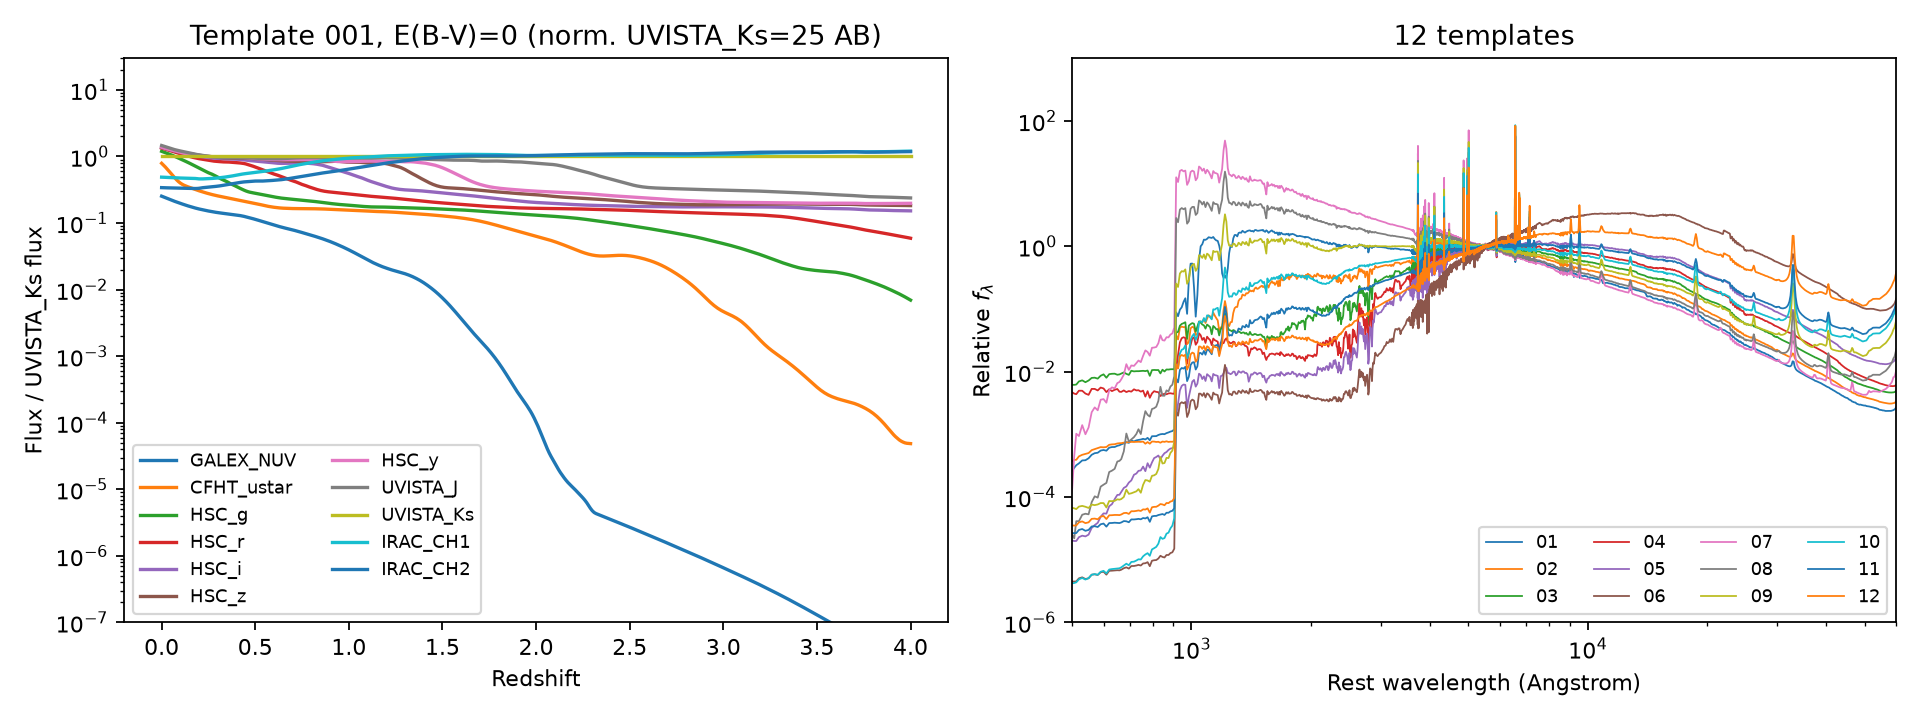

In [11]:
def log(msg: str) -> None:
    # log messages emitted by run(); strip the package-directory prefix so no absolute local paths leak into the output
    print(str(msg).replace(str(PKG) + "/", ""))


result = make_grid.run(make_grid.GridConfig(), progress_every=0, log=log)   # writes to PKG/output/ by default
print("cache hit:", result.cached, "/ elapsed %.2f s" % result.elapsed)
for name, path in result.paths.items():
    print(f"  {name:11s} {rel_path(path)}  ({path.stat().st_size / 1024:.1f} KiB)")

loaded = make_grid.load_grid(result.paths["grid"])
print("npz keys after reload:", sorted(loaded.npz_kwargs()))
print("bitwise identical to the original object:", np.array_equal(loaded.flux, result.grid.flux))

from IPython.display import Image, display
display(Image(filename=str(result.paths["diagnostics"])))


## 6. Equivalent command-line usage and consistency check

The script is itself a directly runnable command-line tool; below is the notebook's equivalent
of calling the very same code.


In [12]:
import subprocess, tempfile

outdir = Path(tempfile.mkdtemp(prefix="make_grid_cli_"))
cmd = [sys.executable, str(PKG / "make_grid.py"),
       "--bands", "HSC_g", "HSC_r", "HSC_i", "HSC_z", "UVISTA_Ks",
       "--n-z", "51", "--n-ebv", "10", "--n-wave", "2000",
       "--output-dir", str(outdir), "--no-diagnostics", "--quiet"]
def shorten(token: str) -> str:
    return token.replace(str(outdir), "$TMP/" + outdir.name).replace(str(PKG) + "/", "")


print("$ python", " ".join(shorten(t) for t in cmd[1:]))
proc = subprocess.run(cmd, capture_output=True, text=True)
print(proc.stdout.strip() or "(no output in --quiet mode)")
print("exit code:", proc.returncode, "/ files written:", sorted(p.name for p in outdir.iterdir()))


$ python make_grid.py --bands HSC_g HSC_r HSC_i HSC_z UVISTA_Ks --n-z 51 --n-ebv 10 --n-wave 2000 --output-dir $TMP/make_grid_cli_lbxk5a60 --no-diagnostics --quiet


(no output in --quiet mode)
exit code: 0 / files written: ['fsps_5band_grid.npz', 'grid_metadata.json']


In [13]:
import hashlib

print("flux sha256:", hashlib.sha256(np.ascontiguousarray(grid.flux).tobytes()).hexdigest())
print("(this is the value quoted in section 9 of README.md)")

# The original notebook's product is not distributed with this repository; look in a few common
# locations and skip the comparison if it is absent
candidates = [
    PKG.parents[1] / "output" / "photoz_datasets" / "fsps_11band_grid.npz",
    PKG.parent / "output" / "photoz_datasets" / "fsps_11band_grid.npz",
    PKG.parents[1] / "output" / "cosmos_fsps_template_grid_11band" / "fsps_11band_grid.npz",
]
original = next((p for p in candidates if p.is_file()), None)
if original is None:
    print("original notebook product not found (it is not distributed with the repository); skipping the bitwise comparison.")
else:
    old = np.load(original)
    print("found original notebook product:", rel_path(original))
    print("flux bitwise identical:", bool(np.array_equal(old["flux"], grid.flux)),
          "/ z and E(B-V) axes identical:", bool(np.array_equal(old["redshift"], grid.redshift) and np.array_equal(old["ebv"], grid.ebv)))


flux sha256: 9083d363bfe3b79a6582c38b975fe917b2856bb0807f9985113df08b8c23fd4f
(this is the value quoted in section 9 of README.md)
found original notebook product: output/photoz_datasets/fsps_11band_grid.npz
flux bitwise identical: True / z and E(B-V) axes identical: True


## Summary

- `build_grid()` / `GridConfig` produce the in-memory grid, `run()` handles writing to disk and
  caching, and `load_grid()` reads it back;
- the grid only carries the **relative flux shape** (reference band = 25 AB); the overall
  amplitude (luminosity distance, etc.) is absorbed by the free amplitude at fit time;
- the command line and the library call share the same numerical implementation; the default
  configuration finishes in about 4 s and is bitwise identical to the original notebook product.

File guide: `make_grid.py` (implementation), `README.md` (documentation), `templates/` (12 FSPS
templates), `filters/` (11 filter response curves + `manifest.json`), `requirements.txt`,
`demo.ipynb` (this file).
